# Shuttle dispatch: plots and validation
This notebook loads results produced by `shuttle.py`; algorithm implementations live in that file.

**Cost convention:** $J(s)$ is the minimum expected discounted **cost**, so smaller is better. If value is defined using reward $r=-c$, its value is $V(s)=-J(s)$.

At each decision, observe queue $s$, choose $a\in\{0,1\}$ (wait/dispatch), serve up to 15 passengers, incur dispatch plus holding cost on the remaining queue, and then receive uniformly distributed arrivals from 1 through 5. The next queue is capped at 200; overflow is discarded without an additional penalty. The finite horizon has 500 decisions and zero terminal cost. All methods use $\gamma=0.95$.

Run `python shuttle.py` first, then **Run All** here. Figures are saved as PNG and PDF under `results/figures/`.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
%matplotlib inline

ROOT = Path.cwd()
if not (ROOT / 'shuttle.py').exists():
    ROOT = ROOT / 'mlds_assignment1_shuttle'
assert (ROOT / 'results/shuttle_results.npz').exists(), 'Run python shuttle.py first.'
data = np.load(ROOT / 'results/shuttle_results.npz')
summary = json.loads((ROOT / 'results/summary.json').read_text())
figures = ROOT / 'results/figures'
figures.mkdir(exist_ok=True)
s = data['states']
plt.rcParams.update({'figure.figsize': (9, 4.8), 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.22})
def save(fig, name):
    fig.tight_layout()
    for extension in ('png', 'pdf'):
        fig.savefig(figures / f'{name}.{extension}', dpi=180, bbox_inches='tight')
    plt.show()


## (a) Finite horizon enumeration, T = 500
Backward induction enumerates both actions and every possible next arrival at each state and decision time. This avoids enumerating exponentially many complete action histories. The terminal value is $J_{500}(s)=0$. The displayed policy at time zero must not be confused with the generally time-dependent finite-horizon policy.

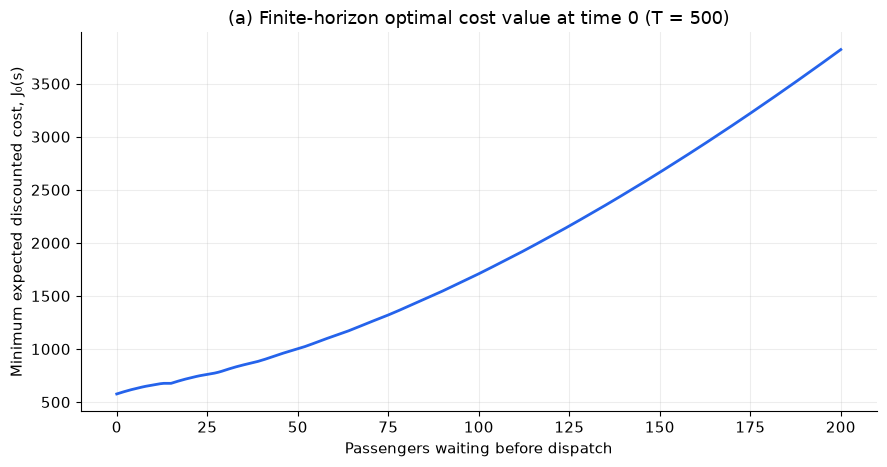

In [2]:
fig, ax = plt.subplots()
ax.plot(s, data['finite_costs'][0], color='#2563eb', linewidth=2)
ax.set(xlabel='Passengers waiting before dispatch', ylabel='Minimum expected discounted cost, J₀(s)',
       title='(a) Finite-horizon optimal cost value at time 0 (T = 500)')
save(fig, 'a_finite_horizon_value')

## (b) Infinite horizon value iteration
Value iteration stops when the maximum Bellman residual is at most $10^{-10}$. The residual divided by $1-\gamma$ bounds the maximum error in the optimal cost value.

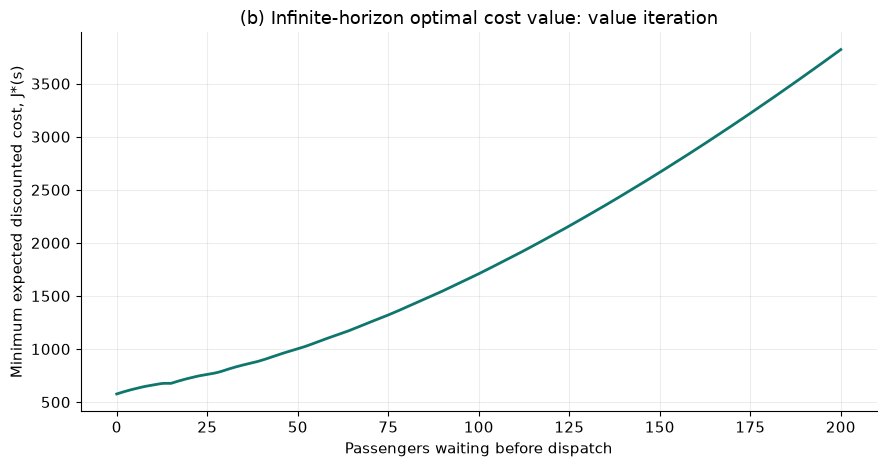

In [3]:
fig, ax = plt.subplots()
ax.plot(s, data['vi_cost'], color='#0f766e', linewidth=2)
ax.set(xlabel='Passengers waiting before dispatch', ylabel='Minimum expected discounted cost, J*(s)',
       title='(b) Infinite-horizon optimal cost value: value iteration')
save(fig, 'b_value_iteration_value')

## (c) Infinite horizon policy iteration
Each policy evaluation solves $(I-\gamma P_\pi)J_\pi=c_\pi$, followed by greedy policy improvement. Ties select wait. The dispatch threshold is inferred from the solved policy, not imposed in the algorithm.

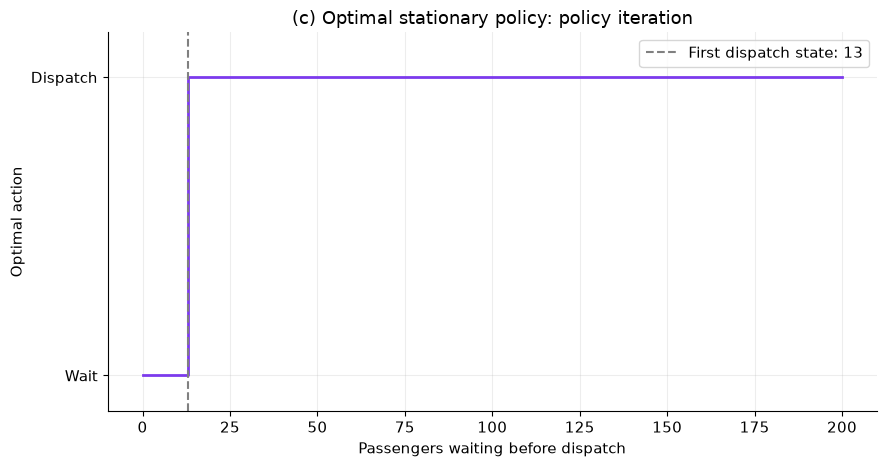

Wait for 0–12 passengers; dispatch for 13–200 passengers.
VI iterations: 518; PI iterations: 6
J*(0) = 576.670167766
J*(15) = 676.670167766
J*(200) = 3821.586477184


In [4]:
threshold = summary['policy_switch_states'][0]
fig, ax = plt.subplots()
ax.step(s, data['pi_policy'], where='post', color='#7c3aed', linewidth=2)
ax.axvline(threshold, linestyle='--', color='gray', label=f'First dispatch state: {threshold}')
ax.set(xlabel='Passengers waiting before dispatch', ylabel='Optimal action',
       title='(c) Optimal stationary policy: policy iteration', ylim=(-0.12, 1.15))
ax.set_yticks([0, 1], ['Wait', 'Dispatch'])
ax.legend()
save(fig, 'c_policy_iteration_policy')
print(f"Wait for 0–{threshold-1} passengers; dispatch for {threshold}–200 passengers.")
print(f"VI iterations: {summary['vi_iterations']}; PI iterations: {summary['pi_iterations']}")
for state in (0, 15, 200):
    print(f'J*({state}) = {data["pi_cost"][state]:.9f}')

## Algorithm agreement and convergence
These comparisons quantify whether the independent solution procedures reach the same answer. The 500-period result differs from the infinite-horizon value only by a discounted tail bounded by $\gamma^{500}c_{\max}/(1-\gamma)$.

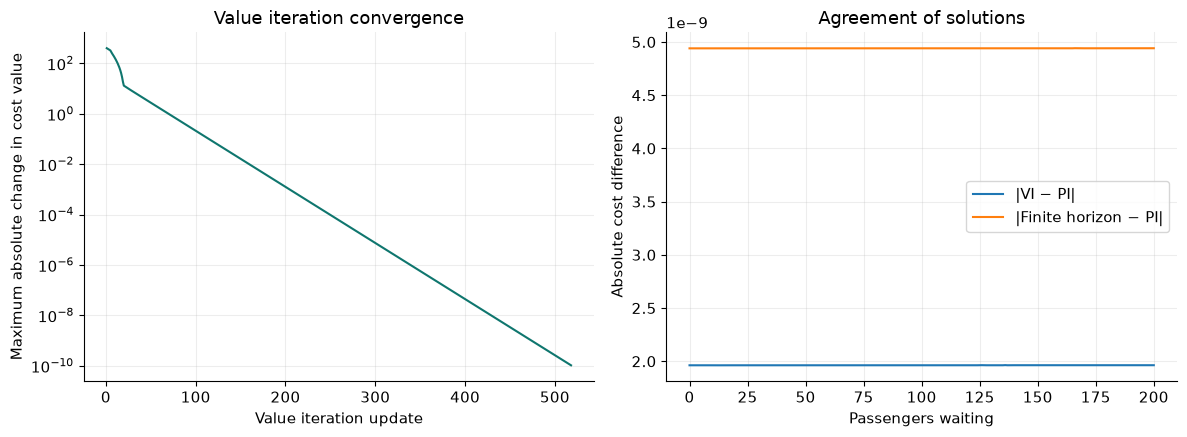

| Experiment | Passed |
|---|---|
| bellman optimality | True |
| vi pi agreement | True |
| finite infinite horizon agreement | True |
| finite terminal condition | True |
| last period is myopic | True |
| boundary transitions | True |
| zero holding cost | True |
| no service no arrivals | True |
| free complete service | True |
| zero discount | True |
| exhaustive small tree | True |
| rollout state 0 | True |
| rollout state 15 | True |
| rollout state 200 | True |

bellman_optimality {'passed': True, 'residual': 9.094947017729282e-13, 'certified_max_value_error': 1.818989403545855e-11}
vi_pi_agreement {'passed': True, 'max_cost_difference': 1.9640538084786385e-09, 'differing_actions': 0}
finite_infinite_horizon_agreement {'passed': True, 'max_cost_difference': 4.9417394620832056e-09, 'theoretical_tail_bound': 6.838022067752704e-08}


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].semilogy(np.arange(1, len(data['vi_changes'])+1), data['vi_changes'], color='#0f766e')
axes[0].set(xlabel='Value iteration update', ylabel='Maximum absolute change in cost value',
            title='Value iteration convergence')
axes[1].plot(s, np.abs(data['vi_cost'] - data['pi_cost']), label='|VI − PI|')
axes[1].plot(s, np.abs(data['finite_costs'][0] - data['pi_cost']), label='|Finite horizon − PI|')
axes[1].set(xlabel='Passengers waiting', ylabel='Absolute cost difference', title='Agreement of solutions')
axes[1].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
axes[1].legend()
save(fig, 'validation_agreement')
checks = summary['validation']
rows = ['| Experiment | Passed |', '|---|---|']
rows += [f"| {name.replace('_', ' ')} | {entry['passed']} |" for name, entry in checks.items()]
display(Markdown('\n'.join(rows)))
for key in ('bellman_optimality', 'vi_pi_agreement', 'finite_infinite_horizon_agreement'):
    print(key, checks[key])

## Independent Monte Carlo check
For each starting queue, 20,000 independent trajectories of 300 decisions use the optimal policy. Bars show $\pm 1.96$ standard errors of the estimated expected discounted cost; crosses show exact linear-system values. The automated check uses a wider four-standard-error tolerance plus a discounted tail bound to avoid a fragile random test. This simulation supports the exact solution but is not itself an optimality proof.

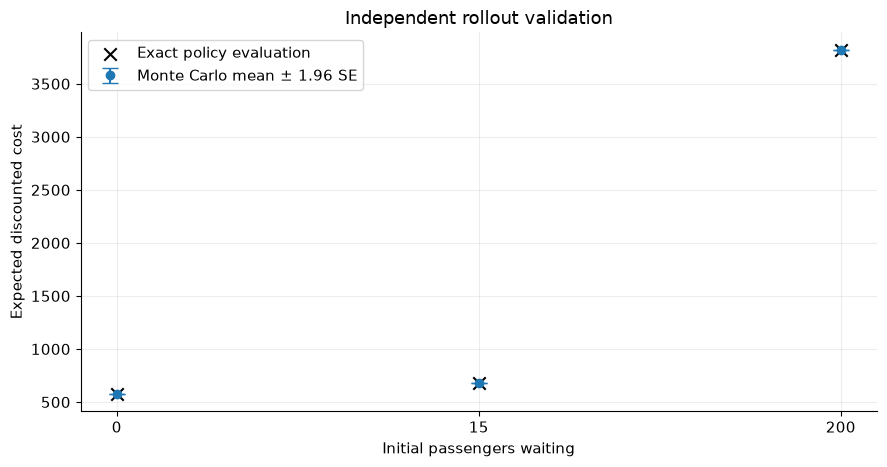

s=0: mean=576.671469, exact=576.670168, SE=0.219213
s=15: mean=676.814669, exact=676.670168, SE=0.221520
s=200: mean=3821.605190, exact=3821.586477, SE=0.532280


In [6]:
rollouts = [summary['validation'][f'rollout_state_{s}'] for s in (0, 15, 200)]
x = np.arange(len(rollouts))
fig, ax = plt.subplots()
ax.errorbar(x, [r['sample_mean'] for r in rollouts],
            yerr=[1.96*r['standard_error'] for r in rollouts], fmt='o', capsize=6, label='Monte Carlo mean ± 1.96 SE')
ax.scatter(x, [r['exact_cost'] for r in rollouts], marker='x', s=80, color='black', label='Exact policy evaluation')
ax.set_xticks(x, [str(r['initial_state']) for r in rollouts])
ax.set(xlabel='Initial passengers waiting', ylabel='Expected discounted cost', title='Independent rollout validation')
ax.legend()
save(fig, 'validation_rollouts')
for r in rollouts:
    print(f"s={r['initial_state']}: mean={r['sample_mean']:.6f}, exact={r['exact_cost']:.6f}, SE={r['standard_error']:.6f}")

## Interpretation and further validation
The optimal threshold is 13, below capacity 15: future holding costs can justify dispatching a partly filled shuttle. In the last finite-horizon period, waiting always wins: a dispatch costs 100 but saves at most $15\times2=30$ in immediate holding cost, and there is no terminal penalty. The infinite-horizon policy therefore must not be applied indiscriminately near the end of a finite horizon.

See `SOLUTION.md` for the Bellman equations, all assumptions, quantitative evidence, edge cases, and a proposed three-month validation plan. These results depend on allowing only one dispatch per decision and on the stated handling of the queue cap.